In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import inspect
from sklearn.model_selection import train_test_split

import store
from core.config import P_COLUMNS, STIFFENER_COLUMNS, REGRESSION_ALWAYS
from core.training import forward_numpy, outputs_to_design


# Compatibilidad con distintas versiones de matplotlib:
#   matplotlib >= 3.9 usa "tick_labels"; antes se usaba "labels".
def boxplot(ax, data, tick_labels, **kw):
    params = inspect.signature(ax.boxplot).parameters
    if "tick_labels" in params:
        ax.boxplot(data, tick_labels=tick_labels, **kw)
    else:
        ax.boxplot(data, labels=tick_labels, **kw)


# 1. Cargar el bundle del modelo
bundle = store.load_model_bundle()
if bundle is None:
    raise RuntimeError("No hay modelo entrenado disponible en store.")
model, pre, device = bundle

# 2. Cargar datos desde data_final.csv y split de TEST
CSV_PATH = store.DATA_DIR / "data_final.csv"
df_resultado = store.build_global_structure_from_final(pd.read_csv(CSV_PATH, sep=";"))
_, df_test = train_test_split(df_resultado, test_size=0.2, random_state=2)

# 3. Inferencia
x_cat, x_num = pre.transform_features(df_test)
outputs = forward_numpy(model, x_cat, x_num, device)
design = outputs_to_design(outputs, pre, geom=df_test).reset_index(drop=True)
real = df_test.reset_index(drop=True)

box_style = dict(
    patch_artist=True,
    boxprops=dict(facecolor='#3498DB', color='#2C3E50', linewidth=1.2, alpha=0.7),
    capprops=dict(color='#2C3E50', linewidth=1.2),
    whiskerprops=dict(color='#2C3E50', linewidth=1.2),
    flierprops=dict(marker='o', markersize=3, markerfacecolor='#E74C3C', alpha=0.3, markeredgecolor='none'),
    medianprops=dict(color='#E74C3C', linewidth=2.0),
)

# ==============================================================================
# GRAFICO 1: Variables de Geometria Global y Rigidizadores
# ==============================================================================
geom_cols = list(REGRESSION_ALWAYS) + list(STIFFENER_COLUMNS) + ["Lh"]
geom_errors, geom_labels = [], []
for col in geom_cols:
    if col in REGRESSION_ALWAYS:
        mask = np.ones(len(real), dtype=bool)
    else:
        mask = real[col].fillna(0.0).values > 0
    if mask.sum() > 0:
        geom_errors.append(design.loc[mask, col].values - real.loc[mask, col].values)
        geom_labels.append(f"{col}\n(N={mask.sum()})")

fig1, ax1 = plt.subplots(figsize=(12, 5), dpi=120)
boxplot(ax1, geom_errors, geom_labels, **box_style)
ax1.axhline(0, color='#2C3E50', linestyle='--', linewidth=1.2, alpha=0.8, label='Error 0 mm')
ax1.set_title("Distribucion del Error de Prediccion: Geometria General y Rigidizadores", fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel("Variables de Placa y Cartabon (Muestras Activas $N$)", fontsize=10, labelpad=8)
ax1.set_ylabel("Error Signado: $Y_{pred} - Y_{real}$ (mm)", fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6, axis='y')
ax1.legend(loc='upper right')
plt.tight_layout()
plt.show()

# ==============================================================================
# GRAFICO 2: Pasos entre tornillos (p1..p12)
# ==============================================================================
p_errors, p_labels = [], []
for col in P_COLUMNS:
    mask = real[col].fillna(0.0).values > 0
    if mask.sum() > 0:
        p_errors.append(design.loc[mask, col].values - real.loc[mask, col].values)
        p_labels.append(f"{col}\n(N={mask.sum()})")

fig2, ax2 = plt.subplots(figsize=(14, 5), dpi=120)
boxplot(ax2, p_errors, p_labels, **box_style)
ax2.axhline(0, color='#2C3E50', linestyle='--', linewidth=1.2, alpha=0.8, label='Error 0 mm')
ax2.set_title("Distribucion del Error de Prediccion por Paso ($p_i$) - TEST (data_final.csv)", fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel("Pasos Relativos ($p_i$) y Muestras Activas ($N$)", fontsize=10, labelpad=8)
ax2.set_ylabel("Error Signado: $p_{pred} - p_{real}$ (mm)", fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6, axis='y')
ax2.legend(loc='upper right')

# Descomentar si deseas fijar la escala vertical y omitir outliers muy lejanos:
# ax2.set_ylim(-40, 40)

plt.tight_layout()
plt.show()


RuntimeError: Error(s) in loading state_dict for ConnectionDesignNet:
	Unexpected key(s) in state_dict: "E_slot.weight", "E_role.weight", "E_na.weight", "E_nc.weight", "head_p_value.0.0.weight", "head_p_value.0.0.bias", "head_p_value.0.2.weight", "head_p_value.0.2.bias", "head_p_value.1.0.weight", "head_p_value.1.0.bias", "head_p_value.1.2.weight", "head_p_value.1.2.bias", "head_p_value.2.0.weight", "head_p_value.2.0.bias", "head_p_value.2.2.weight", "head_p_value.2.2.bias", "head_p_value.3.0.weight", "head_p_value.3.0.bias", "head_p_value.3.2.weight", "head_p_value.3.2.bias", "head_p_value.4.0.weight", "head_p_value.4.0.bias", "head_p_value.4.2.weight", "head_p_value.4.2.bias", "head_p_value.5.0.weight", "head_p_value.5.0.bias", "head_p_value.5.2.weight", "head_p_value.5.2.bias", "head_p_value.6.0.weight", "head_p_value.6.0.bias", "head_p_value.6.2.weight", "head_p_value.6.2.bias", "head_p_value.7.0.weight", "head_p_value.7.0.bias", "head_p_value.7.2.weight", "head_p_value.7.2.bias", 

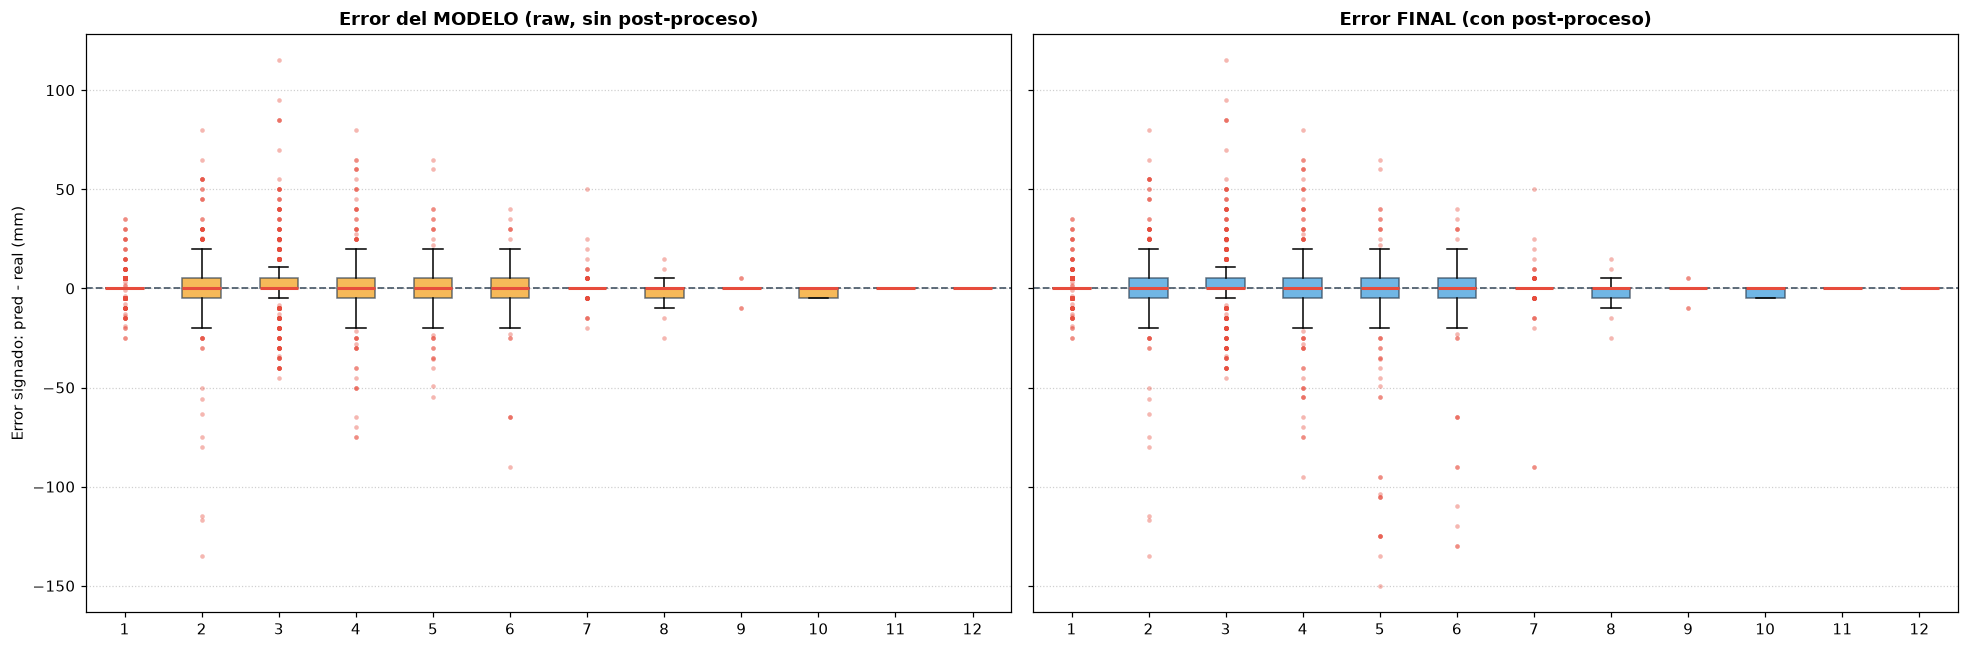

Outliers < -20 mm:  modelo(raw)=91  final(post)=115  (delta=24)
Outliers > +20 mm:  modelo(raw)=144  final(post)=143  (delta=-1)


In [6]:
# =============================================================================
# D) Comparativa: error del MODELO (raw, sin post-proceso) vs error FINAL
#    - raw  = salida cruda de la cabeza de regresion (inverse_masked), sin mascara
#             ni clamp. Aisla el error propio del modelo.
#    - final = diseno post-procesado (Regla 1/2). Aisla el efecto del post-proceso.
# =============================================================================
raw_all = pre.inverse_masked(outputs["masked_value"])
P_raw = np.round(raw_all[:, :12] / 5) * 5   # valor crudo del modelo en la misma rejilla

errors_raw, errors_fin, labels2 = [], [], []
for j, col in enumerate(P_COLUMNS):
    m = real[col].fillna(0.0).values > 0
    if m.sum() > 0:
        errors_raw.append(P_raw[m, j] - real.loc[m, col].values)
        errors_fin.append(design.loc[m, col].values - real.loc[m, col].values)
        labels2.append(f"{col}\n(N={int(m.sum())})")

fig, axes = plt.subplots(1, 2, figsize=(18, 6), dpi=110, sharey=True)
for ax, data, ttl, col in [
    (axes[0], errors_raw, "Error del MODELO (raw, sin post-proceso)", '#F39C12'),
    (axes[1], errors_fin, "Error FINAL (con post-proceso)", '#3498DB'),
]:
    ax.boxplot(
        data, label=labels2, patch_artist=True,
        boxprops=dict(facecolor=col, color='#2C3E50', linewidth=1.0, alpha=0.7),
        medianprops=dict(color='#E74C3C', linewidth=2.0),
        flierprops=dict(marker='o', markersize=3, markerfacecolor='#E74C3C', alpha=0.4, markeredgecolor='none'),
    )
    ax.axhline(0, color='#2C3E50', linestyle='--', linewidth=1.2, alpha=0.8)
    ax.set_title(ttl, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.6, axis='y')
axes[0].set_ylabel("Error signado: pred - real (mm)")
plt.tight_layout()
plt.show()

neg_raw = int(sum((e < -20).sum() for e in errors_raw))
neg_fin = int(sum((e < -20).sum() for e in errors_fin))
pos_raw = int(sum((e > 20).sum() for e in errors_raw))
pos_fin = int(sum((e > 20).sum() for e in errors_fin))
print(f"Outliers < -20 mm:  modelo(raw)={neg_raw}  final(post)={neg_fin}  (delta={neg_fin - neg_raw})")
print(f"Outliers > +20 mm:  modelo(raw)={pos_raw}  final(post)={pos_fin}  (delta={pos_fin - pos_raw})")
